ROC and AUC 

In [ ]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification
from sklearn.metrics import roc_curve,roc_auc_score

In [25]:
from matplotlib import pyplot

In [3]:
X,y  = make_classification(n_samples=1000,n_classes=2,random_state=42)

In [5]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.30,random_state=42)

In [ ]:
## Dummy model with default 0 as output Majority class
dummy_model_prob = [0 for i in range(len(y_test))]

In [9]:
model  = LogisticRegression() 
penalty = ['l1','l2','elasticnet','none']
c_values = [0.001,0.01,0.1,1,10,100]
solver = ['newton-cg','lbfgs','liblinear','sag','saga']


In [10]:
params = [
    {
        'penalty': ['l1'],
        'C': c_values,
        'solver': ['liblinear', 'saga']
    },
    {
        'penalty': ['l2'],
        'C': c_values,
        'solver': ['lbfgs', 'liblinear', 'sag', 'saga']
    }
]

In [11]:
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
grid = GridSearchCV(
    model,
    params,
    cv=cv,
    n_jobs=-1
)


In [12]:
model.fit(X_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [13]:
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score

In [ ]:
y_pred = model.predict(X_test)
print(classification_report(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))
print(accuracy_score(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.82      0.88      0.85       145
           1       0.88      0.83      0.85       155

    accuracy                           0.85       300
   macro avg       0.85      0.85      0.85       300
weighted avg       0.85      0.85      0.85       300

[[127  18]
 [ 27 128]]
0.85


In [17]:
## prediction based on probability
model_prob= model.predict_proba(X_test)


In [ ]:
## focus on the probability of the positive class (class 1) Only 
model_prob = model_prob[:,1]

In [19]:
model_prob

array([6.09536672e-01, 8.68929260e-01, 5.13909465e-01, 7.79089383e-01,
       9.53723656e-01, 5.23451932e-02, 2.27636761e-01, 7.89347054e-01,
       7.37037455e-01, 3.12417654e-01, 9.66424758e-01, 6.70829492e-01,
       4.08948143e-03, 4.99306936e-01, 7.19672711e-01, 1.79605592e-01,
       6.44589971e-02, 9.51291957e-01, 8.87630911e-01, 4.78687093e-01,
       9.94347672e-01, 2.55081828e-01, 5.14401674e-02, 1.02764693e-01,
       9.78692448e-01, 4.51196086e-03, 9.99621703e-01, 9.37634035e-01,
       1.18188476e-02, 9.69791848e-01, 8.68816110e-01, 9.88422095e-01,
       6.15473106e-01, 1.47860299e-01, 3.12980543e-01, 1.65110252e-01,
       7.00945658e-02, 4.04964522e-01, 4.55256562e-02, 2.76558176e-01,
       1.86227131e-02, 9.48312870e-01, 5.57726753e-02, 4.53793669e-01,
       5.01184326e-01, 1.14111255e-02, 9.92328859e-01, 5.41306342e-03,
       8.59704303e-01, 9.90278194e-01, 7.62490429e-02, 7.65075587e-02,
       1.00222414e-02, 9.96565652e-01, 9.96836896e-01, 6.70517119e-01,
      

In [22]:
dummy_model_auc = roc_auc_score(y_test,dummy_model_prob)
model_auc = roc_auc_score(y_test,model_prob)
print(dummy_model_auc,model_auc)

0.5 0.9141713014460511


In [28]:
## calculate the ROC curve
## third parameter is threshold which we are not using here
dummy_fpr , dummy_tpr, _ = roc_curve(y_test,dummy_model_prob)
model_fpr , model_tpr, threshold = roc_curve(y_test,model_prob)

In [ ]:
threshold
## we are able to see the threshold values 

array([           inf, 9.99903312e-01, 9.60819585e-01, 9.60673656e-01,
       9.42928905e-01, 9.37634035e-01, 9.35829937e-01, 9.35196941e-01,
       9.33388706e-01, 9.31568682e-01, 9.19898462e-01, 9.18320734e-01,
       9.08848834e-01, 9.04149376e-01, 8.68929260e-01, 8.68816110e-01,
       8.59454363e-01, 8.57330834e-01, 7.66609556e-01, 7.56307961e-01,
       7.47504157e-01, 7.44341554e-01, 7.38336625e-01, 7.35803961e-01,
       7.28263642e-01, 7.19672711e-01, 6.70517119e-01, 6.64080329e-01,
       5.97992204e-01, 5.63115004e-01, 5.61146495e-01, 5.42332260e-01,
       5.33104469e-01, 5.18849321e-01, 4.67721242e-01, 4.66279420e-01,
       4.53793669e-01, 4.43620311e-01, 4.30357018e-01, 4.30169935e-01,
       4.29200970e-01, 3.96059977e-01, 3.47982821e-01, 3.34198768e-01,
       3.28119070e-01, 3.07874692e-01, 2.95655789e-01, 2.40142099e-01,
       2.39704326e-01, 1.97988953e-01, 1.92236077e-01, 1.72072589e-01,
       1.68324514e-01, 1.44381585e-01, 1.41194398e-01, 1.36275906e-01,
      

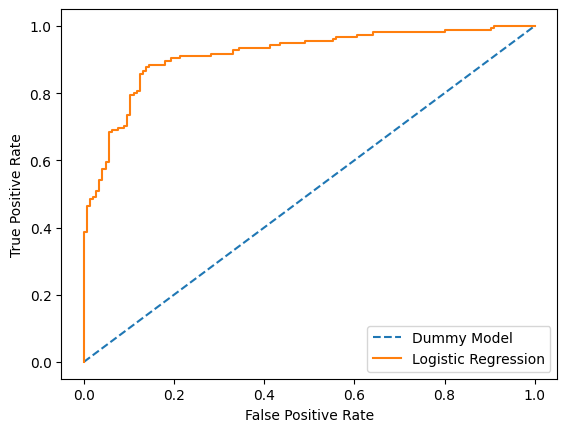

In [30]:
## plotting the Roc curve for model 
pyplot.plot(dummy_fpr,dummy_tpr,linestyle='--',label="Dummy Model")
pyplot.plot(model_fpr,model_tpr,label="Logistic Regression")
pyplot.legend()
pyplot.xlabel("False Positive Rate")
pyplot.ylabel("True Positive Rate")
pyplot.show()
            

In [ ]:
## logistic refression perform well than Dummy well Because Area Under curve AUC   Is more for logistic regression than Dummy model. AUC is 0.5 for Dummy model and 0.9 for Logistic Regression

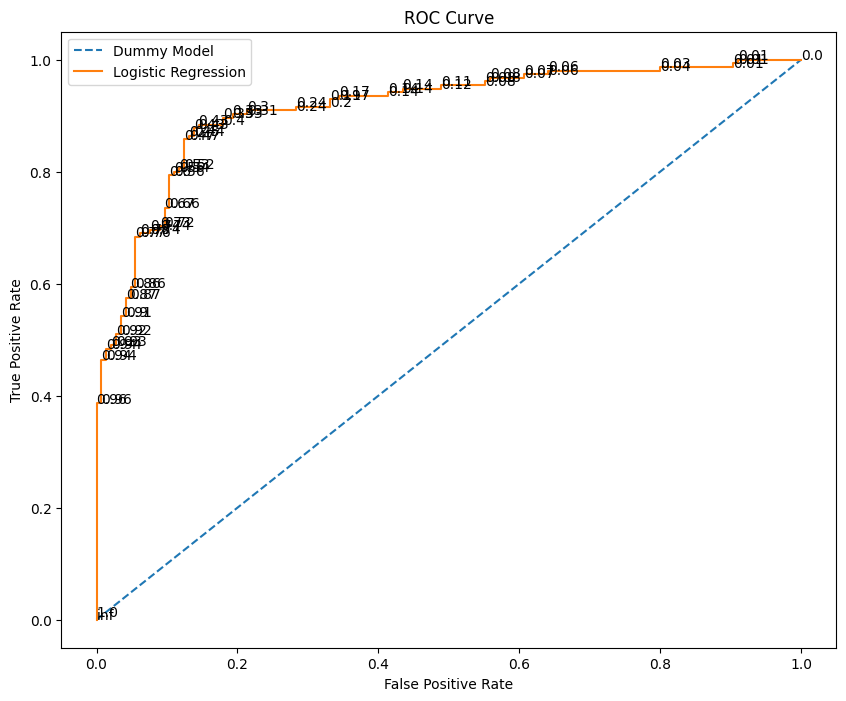

In [34]:
## plotting with threeshold 
fig, ax = pyplot.subplots(figsize=(10, 8))

ax.plot(
    dummy_fpr,
    dummy_tpr,
    linestyle='--',
    label="Dummy Model"
)

ax.plot(
    model_fpr,
    model_tpr,
    label="Logistic Regression"
)

for fpr, tpr, threshold in zip(model_fpr, model_tpr, threshold):
    ax.annotate(
        np.round(threshold, 2),
        xy=(fpr, tpr)
    )

ax.legend()
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve")

pyplot.show()